In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sample_1000.csv")
df.head()

,ID,Severity,Start_Time,Start_Lat,Start_Lng,State,Temperature(F),Visibility(mi),Weather_Condition
0,A-4744146,2,2022-08-21 15:44:01.000000000,29.268300,-82.193723,FL,75.0,1.0,Heavy T-Storm / Windy
1,A-4106985,2,2023-01-16 01:59:00,35.250676,-80.844333,NC,32.0,10.0,Fair
2,A-5904724,2,2021-07-09 18:34:40.000000000,25.926882,-80.207441,FL,86.0,10.0,Fair
3,A-4857546,2,2022-05-19 14:49:45,25.956173,-80.205572,FL,90.0,10.0,Fair
4,A-7455018,3,2019-02-27 20:26:14,41.822600,-87.916370,IL,19.9,10.0,Partly Cloudy


In [2]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.info()

Rows: 1000
Columns: 9
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 1000 non-null   object 
 1   Severity           1000 non-null   int64  
 2   Start_Time         1000 non-null   object 
 3   Start_Lat          1000 non-null   float64
 4   Start_Lng          1000 non-null   float64
 5   State              1000 non-null   object 
 6   Temperature(F)     988 non-null    float64
 7   Visibility(mi)     984 non-null    float64
 8   Weather_Condition  984 non-null    object 
dtypes: float64(4), int64(1), object(4)
memory usage: 70.4+ KB


In [3]:
df.dtypes.value_counts()

object     4
float64    4
int64      1
Name: count, dtype: int64

In [4]:
feature_table = pd.DataFrame({
    "Feature": df.columns,
    "Type": df.dtypes.values,
    "Non-Null": df.notnull().sum().values,
    "Unique": df.nunique().values,
    "Example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
})
feature_table

,Feature,Type,Non-Null,Unique,Example
0,ID,object,1000,1000,A-4744146
1,Severity,int64,1000,4,2
2,Start_Time,object,1000,1000,2022-08-21 15:44:01.000000000
3,Start_Lat,float64,1000,999,29.2683
4,Start_Lng,float64,1000,999,-82.193723
5,State,object,1000,40,FL
6,Temperature(F),float64,988,174,75.0
7,Visibility(mi),float64,984,21,1.0
8,Weather_Condition,object,984,32,Heavy T-Storm / Windy


In [5]:
df.describe().T                      # numeric
df.describe(include="object").T      # categorical

,count,unique,top,freq
ID,1000,1000,A-3837282,1
Start_Time,1000,1000,2022-02-10 11:24:06,1
State,1000,40,CA,224
Weather_Condition,984,32,Fair,337


In [6]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing": missing, "Percent": missing_pct})
missing_df[missing_df.Missing > 0].sort_values("Percent", ascending=False)

,Missing,Percent
Visibility(mi),16,1.6
Weather_Condition,16,1.6
Temperature(F),12,1.2


In [7]:
missing = df.isnull().sum()
missing_df = pd.DataFrame({
    "Missing": missing,
    "Percent": (missing / len(df) * 100).round(2)
})
m = missing_df[missing_df.Missing > 0].sort_values("Percent", ascending=False)

m.style.bar(subset="Percent", color="#d65f5f", vmin=0, vmax=100)

,Missing,Percent
Visibility(mi),16,1.600000
Weather_Condition,16,1.600000
Temperature(F),12,1.200000


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Severity
1      9
2    798
3    169
4     24
Name: count, dtype: int64
Severity
1    0.009
2    0.798
3    0.169
4    0.024
Name: count, dtype: float64


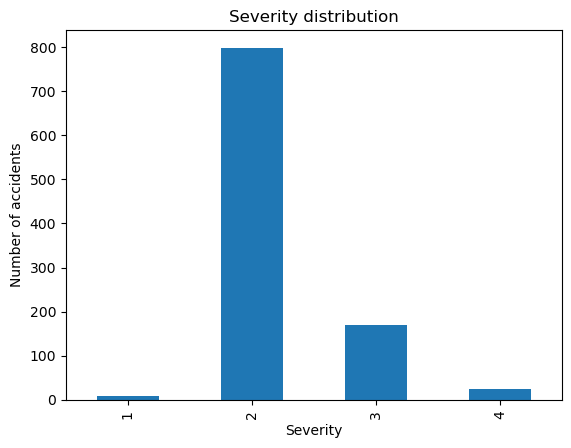

In [9]:
target = "Severity"

counts = df[target].value_counts().sort_index()
print(counts)
print((counts / len(df)).round(3))

counts.plot(kind="bar", title="Severity distribution")
plt.xlabel("Severity")
plt.ylabel("Number of accidents")
plt.show()

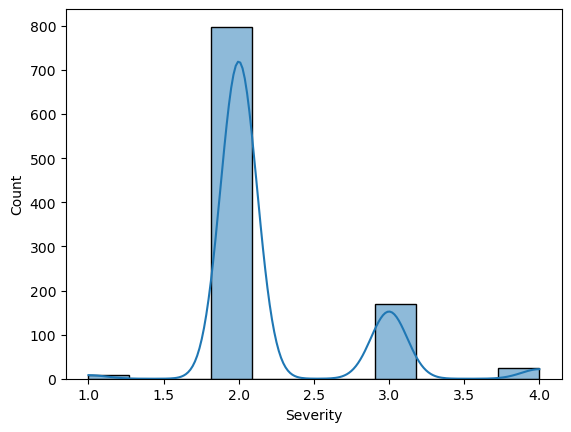

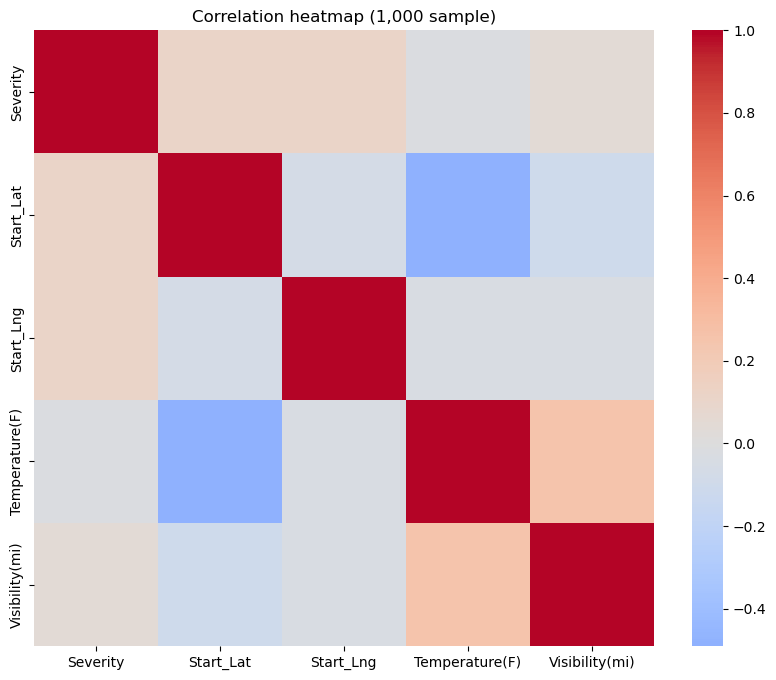

In [10]:
sample = df.sample(min(200_000, len(df)), random_state=42)

sns.histplot(sample["Severity"], kde=True)   # regression target
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(sample.select_dtypes("number").corr(), cmap="coolwarm", center=0)
plt.title(f"Correlation heatmap ({len(sample):,} sample)")
plt.show()

In [14]:
df["Start_Time"] = pd.to_datetime(
    df["Start_Time"].astype(str).str[:19],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce",
)

print(df["Start_Time"].min(), "to", df["Start_Time"].max())
print("Unparsed dates:", df["Start_Time"].isna().sum())
print(df["Start_Time"].dt.year.value_counts().sort_index())

2016-04-18 13:36:48 to 2023-03-30 09:22:00
Unparsed dates: 0
Start_Time
2016     53
2017     89
2018    130
2019    116
2020    140
2021    201
2022    243
2023     28
Name: count, dtype: int64
